<a href="https://colab.research.google.com/github/Reysanx/dashboard-superstore/blob/main/Comparacion_Matplotlib_Seaborn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import os
from google.colab import userdata

# Lee el secreto de forma segura sin escribirlo en el código
kaggle_token = userdata.get('KAGGLE_API_TOKEN')
os.environ['KAGGLE_API_TOKEN'] = kaggle_token

!mkdir -p ~/.kaggle
with open(os.path.expanduser('~/.kaggle/access_token'), 'w') as f:
    f.write(kaggle_token)
!chmod 600 ~/.kaggle/access_token

!pip install -q --upgrade kaggle
!kaggle datasets download -d vivek468/superstore-dataset-final
!unzip -o superstore-dataset-final.zip

Dataset URL: https://www.kaggle.com/datasets/vivek468/superstore-dataset-final
License(s): other
superstore-dataset-final.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  superstore-dataset-final.zip
  inflating: Sample - Superstore.csv  


/tmp/ipykernel_1393/1392881447.py:47: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2, 0].boxplot(datos_regiones, labels=regiones, patch_artist=True,


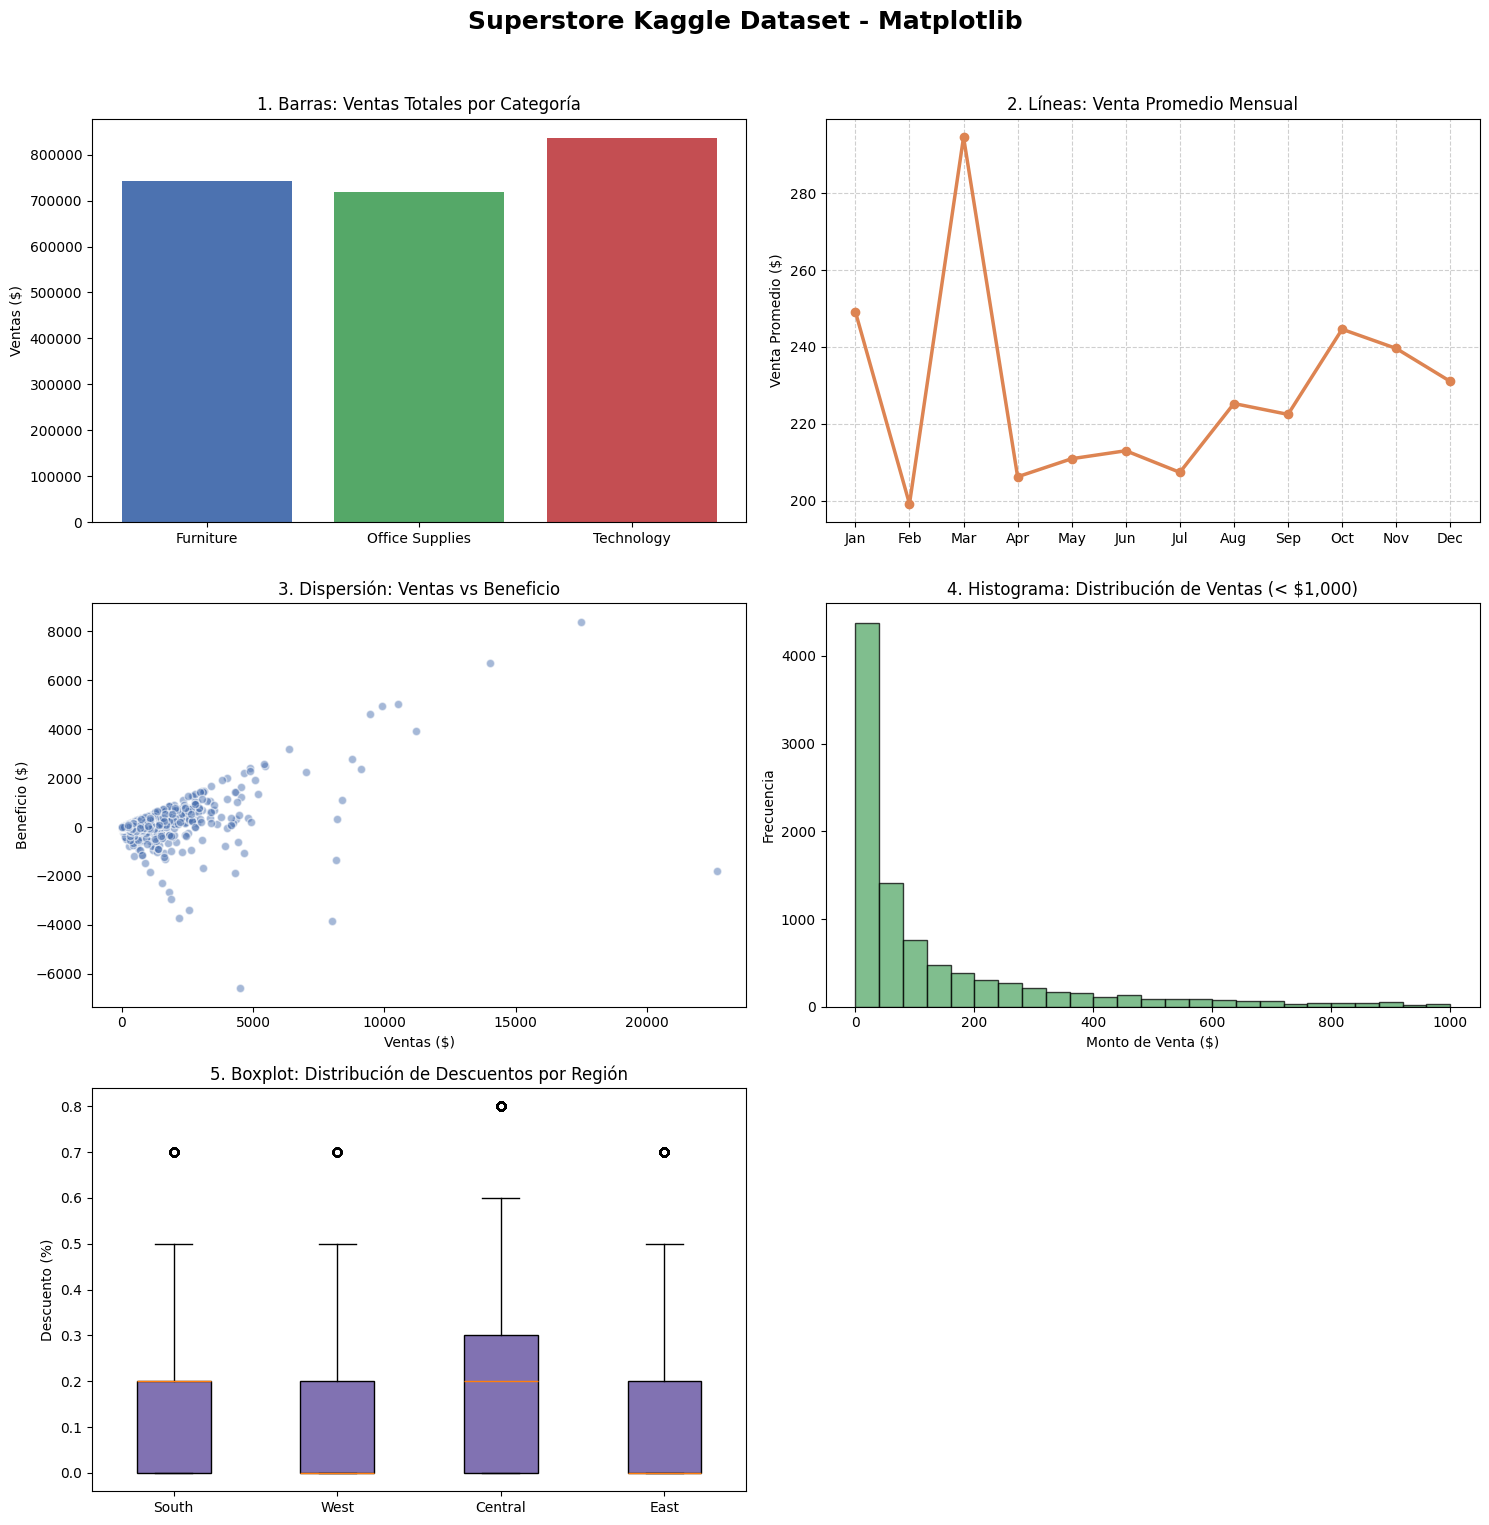

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar dataset (codificación latin1 requerida por este CSV de Kaggle)
df = pd.read_csv('Sample - Superstore.csv', encoding='latin1')

# Preparar columnas de fecha para el gráfico de líneas
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Mes_Num'] = df['Order Date'].dt.month
df['Mes'] = df['Order Date'].dt.strftime('%b')

# --- MATPLOTLIB ---
fig, axes = plt.subplots(3, 2, figsize=(15, 16))
fig.suptitle('Superstore Kaggle Dataset - Matplotlib', fontsize=18, fontweight='bold')

# 1. Gráfico de Barras: Ventas totales por Categoría
ventas_cat = df.groupby('Category')['Sales'].sum()
axes[0, 0].bar(ventas_cat.index, ventas_cat.values, color=['#4C72B0', '#55A868', '#C44E52'])
axes[0, 0].set_title('1. Barras: Ventas Totales por Categoría')
axes[0, 0].set_ylabel('Ventas ($)')

# 2. Gráfico de Líneas: Promedio de ventas por mes
ventas_mes = df.groupby(['Mes_Num', 'Mes'])['Sales'].mean().reset_index().sort_values('Mes_Num')
axes[0, 1].plot(ventas_mes['Mes'], ventas_mes['Sales'], marker='o', linewidth=2.5, color='#DD8452')
axes[0, 1].set_title('2. Líneas: Venta Promedio Mensual')
axes[0, 1].set_ylabel('Venta Promedio ($)')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# 3. Dispersión: Ventas vs Beneficio (Profit)
axes[1, 0].scatter(df['Sales'], df['Profit'], alpha=0.5, color='#4C72B0', edgecolors='w')
axes[1, 0].set_title('3. Dispersión: Ventas vs Beneficio')
axes[1, 0].set_xlabel('Ventas ($)')
axes[1, 0].set_ylabel('Beneficio ($)')

# 4. Histograma: Distribución de Ventas (filtrado < 1000$ para evitar sesgo extremo)
ventas_filtradas = df[df['Sales'] < 1000]['Sales']
axes[1, 1].hist(ventas_filtradas, bins=25, color='#55A868', edgecolor='black', alpha=0.75)
axes[1, 1].set_title('4. Histograma: Distribución de Ventas (< $1,000)')
axes[1, 1].set_xlabel('Monto de Venta ($)')
axes[1, 1].set_ylabel('Frecuencia')

# 5. Boxplot: Descuentos aplicados por Región
regiones = df['Region'].unique()
datos_regiones = [df[df['Region'] == r]['Discount'] for r in regiones]
axes[2, 0].boxplot(datos_regiones, labels=regiones, patch_artist=True,
                   boxprops=dict(facecolor='#8172B2', color='black'))
axes[2, 0].set_title('5. Boxplot: Distribución de Descuentos por Región')
axes[2, 0].set_ylabel('Descuento (%)')

axes[2, 1].axis('off')
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

/tmp/ipykernel_1393/70596887.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Category', y='Sales', estimator=sum, errorbar=None, palette='muted', ax=axes[0, 0])
/tmp/ipykernel_1393/70596887.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Region', y='Discount', palette='pastel', ax=axes[2, 0])


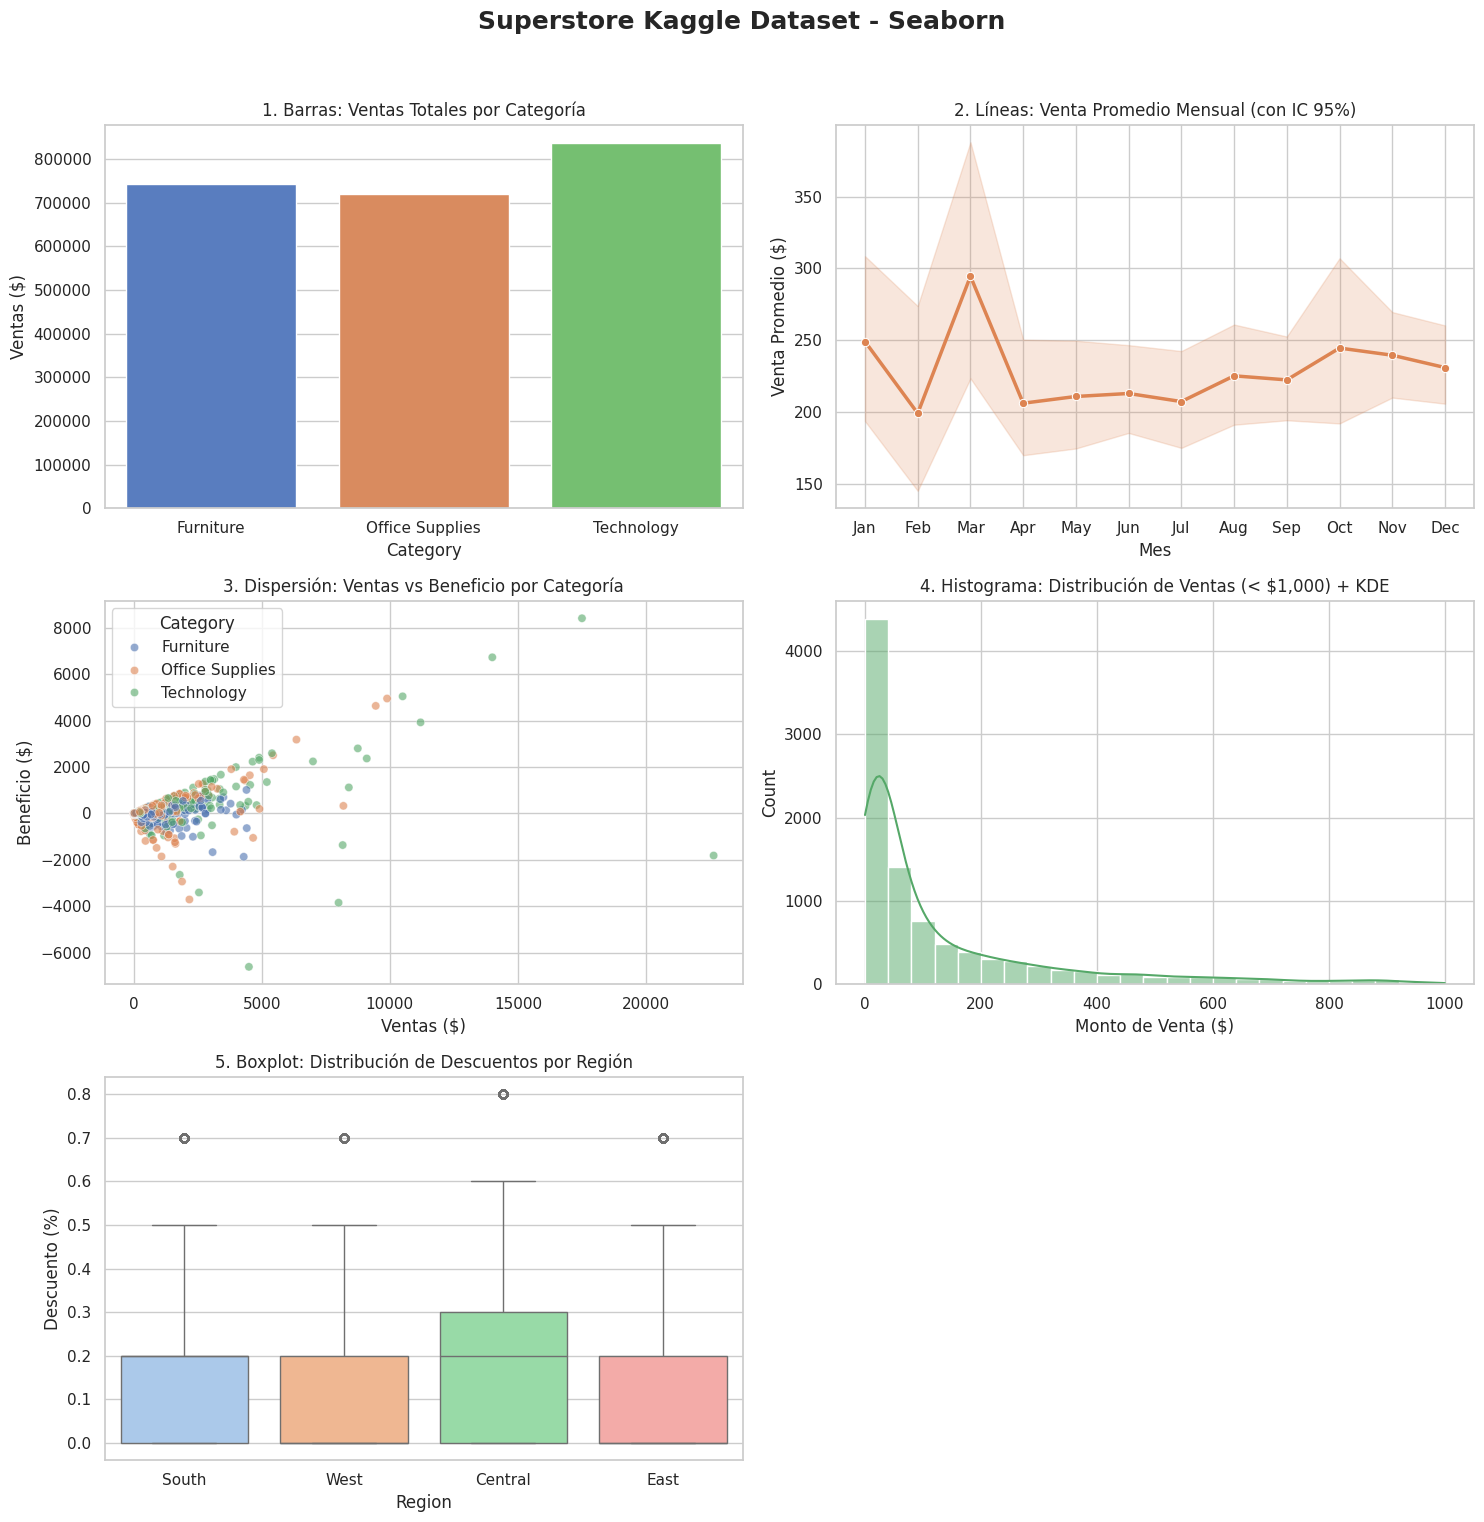

In [10]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(15, 16))
fig.suptitle('Superstore Kaggle Dataset - Seaborn', fontsize=18, fontweight='bold')

# 1. Barras
sns.barplot(data=df, x='Category', y='Sales', estimator=sum, errorbar=None, palette='muted', ax=axes[0, 0])
axes[0, 0].set_title('1. Barras: Ventas Totales por Categoría')
axes[0, 0].set_ylabel('Ventas ($)')

# 2. Líneas
df_sorted = df.sort_values('Mes_Num')
sns.lineplot(data=df_sorted, x='Mes', y='Sales', marker='o', linewidth=2.5, color='#DD8452', ax=axes[0, 1])
axes[0, 1].set_title('2. Líneas: Venta Promedio Mensual (con IC 95%)')
axes[0, 1].set_ylabel('Venta Promedio ($)')

# 3. Dispersión
sns.scatterplot(data=df, x='Sales', y='Profit', hue='Category', alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title('3. Dispersión: Ventas vs Beneficio por Categoría')
axes[1, 0].set_xlabel('Ventas ($)')
axes[1, 0].set_ylabel('Beneficio ($)')

# 4. Histograma
sns.histplot(data=df[df['Sales'] < 1000], x='Sales', bins=25, kde=True, color='#55A868', ax=axes[1, 1])
axes[1, 1].set_title('4. Histograma: Distribución de Ventas (< $1,000) + KDE')
axes[1, 1].set_xlabel('Monto de Venta ($)')

# 5. Boxplot
sns.boxplot(data=df, x='Region', y='Discount', palette='pastel', ax=axes[2, 0])
axes[2, 0].set_title('5. Boxplot: Distribución de Descuentos por Región')
axes[2, 0].set_ylabel('Descuento (%)')

axes[2, 1].axis('off')
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

In [11]:
%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(page_title="Superstore Dashboard", layout="wide")
st.title("📊 Dashboard de Ventas - Superstore (Kaggle)")

@st.cache_data
def load_data():
    df = pd.read_csv('Sample - Superstore.csv', encoding='latin1')
    df['Order Date'] = pd.to_datetime(df['Order Date'])
    df['Mes_Num'] = df['Order Date'].dt.month
    df['Mes'] = df['Order Date'].dt.strftime('%b')
    return df

df = load_data()

# Sidebar para filtros
st.sidebar.header("Filtros de Exploración")
regiones = st.sidebar.multiselect(
    "Selecciona Regiones:",
    options=df['Region'].unique(),
    default=df['Region'].unique()
)
df_filt = df[df['Region'].isin(regiones)]

# --- FILA 1: Barras y Líneas ---
col1, col2 = st.columns(2)
with col1:
    st.subheader("1. Ventas Totales por Categoría")
    ventas_cat = df_filt.groupby('Category')['Sales'].sum()
    st.bar_chart(ventas_cat, color="#4C72B0")

with col2:
    st.subheader("2. Venta Promedio Mensual")
    ventas_mes = df_filt.groupby(['Mes_Num', 'Mes'])['Sales'].mean().reset_index().sort_values('Mes_Num')
    st.line_chart(ventas_mes.set_index('Mes')['Sales'], color="#DD8452")

st.divider()

# --- FILA 2: Dispersión e Histograma ---
col3, col4 = st.columns(2)
with col3:
    st.subheader("3. Dispersión: Ventas vs Beneficio")
    st.scatter_chart(data=df_filt, x='Sales', y='Profit', color='Category')

with col4:
    st.subheader("4. Histograma: Ventas (< $1,000)")
    fig_hist, ax_hist = plt.subplots(figsize=(8, 4.5))
    sns.histplot(data=df_filt[df_filt['Sales'] < 1000], x='Sales', bins=25, kde=True, color='#55A868', ax=ax_hist)
    ax_hist.set_xlabel("Monto de Venta ($)")
    st.pyplot(fig_hist)

st.divider()

# --- FILA 3: Boxplot ---
st.subheader("5. Boxplot: Descuentos por Región")
fig_box, ax_box = plt.subplots(figsize=(12, 4))
sns.boxplot(data=df_filt, x='Region', y='Discount', palette='pastel', ax=ax_box)
ax_box.set_ylabel("Descuento (%)")
st.pyplot(fig_box)

Overwriting app.py


In [12]:
%%writefile requirements.txt
streamlit
pandas
matplotlib
seaborn

Overwriting requirements.txt


In [13]:
!pip install -q PyGithub

from github import Github, Auth
from google.colab import userdata

# 1. Autenticación segura usando los Secretos de Colab
token = userdata.get('GITHUB_TOKEN')
g = Github(auth=Auth.Token(token))

# 2. Conectar con tu repositorio (formato: "tu_usuario/nombre_repo")
repo = g.get_repo("Reysanx/dashboard-superstore")

# 3. Lista de archivos generados en Colab que queremos subir
archivos = ["app.py", "requirements.txt", "Sample - Superstore.csv"]

for nombre_archivo in archivos:
    with open(nombre_archivo, "rb") as f:
        contenido = f.read()

    try:
        # Si el archivo ya existe en el repo, lo actualiza
        archivo_existente = repo.get_contents(nombre_archivo)
        repo.update_file(
            path=nombre_archivo,
            message=f"Actualización de {nombre_archivo} desde Colab",
            content=contenido,
            sha=archivo_existente.sha
        )
        print(f"🔄 Actualizado: {nombre_archivo}")
    except Exception:
        # Si no existe, lo crea nuevo
        repo.create_file(
            path=nombre_archivo,
            message=f"Subida inicial de {nombre_archivo} desde Colab",
            content=contenido
        )
        print(f"✅ Creado: {nombre_archivo}")

✅ Creado: app.py
✅ Creado: requirements.txt
✅ Creado: Sample - Superstore.csv
